In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Cargamos los datos directamente desde una URL pública
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Inspección inicial de la estructura y tipos de datos
print("Dimensiones del dataset:", df.shape)
df.info()

Dimensiones del dataset: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [2]:
# 1. Identificar valores nulos
print(df.isnull().sum())

# 2. Estrategia de Imputación
# Para la edad (Age), rellenamos con la mediana porque es menos sensible a valores atípicos que la media
df['Age'] = df['Age'].fillna(df['Age'].median())

# Para el puerto de embarque (Embarked), rellenamos con el valor más frecuente (moda)
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# La cabina (Cabin) tiene demasiados nulos, la descartamos por ahora para simplificar
df = df.drop(columns=['Cabin'])

print("Nulos restantes:\n", df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Nulos restantes:
 PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


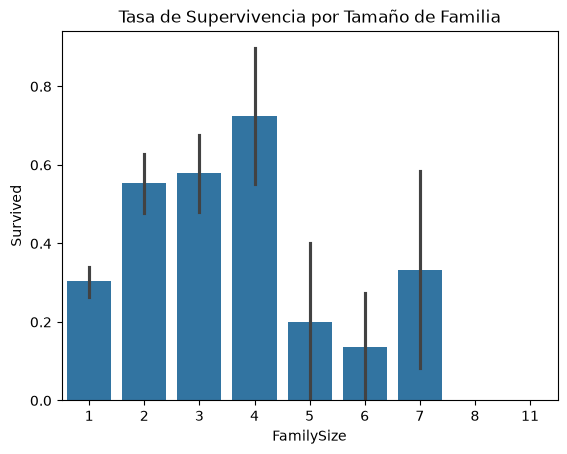

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,S,2,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C,2,0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,S,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,S,2,0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,S,1,1


In [3]:
# Creando una nueva variable 'FamilySize' sumando hermanos/cónyuges (SibSp) y padres/hijos (Parch)
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1 

# Creando una variable binaria 'IsAlone' (¿Viajaba solo?)
df['IsAlone'] = 0
df.loc[df['FamilySize'] == 1, 'IsAlone'] = 1

# Transformando variables categóricas a numéricas (One-Hot Encoding básico)
# Las máquinas no entienden "male" o "female", necesitan 0 y 1.
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

# Visualización rápida de la supervivencia según el tamaño de la familia
sns.barplot(x='FamilySize', y='Survived', data=df)
plt.title('Tasa de Supervivencia por Tamaño de Familia')
plt.show()

# Ver las primeras filas de nuestro dataset procesado
df.head()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Definir nuestras variables predictoras (X) y nuestra variable objetivo (y)
features = ['Sex', 'Age', 'FamilySize', 'IsAlone']
X = df[features]
y = df['Survived']

# 2. Dividir los datos: 80% para entrenar el modelo, 20% para examinarlo
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Inicializar y entrenar (ajustar) el modelo
modelo_rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
modelo_rf.fit(X_train, y_train)

# 4. Hacer predicciones sobre los datos de prueba ocultos (X_test)
predicciones = modelo_rf.predict(X_test)

# 5. Medir el rendimiento (Accuracy)
precision = accuracy_score(y_test, predicciones)
print(f"Precisión inicial del modelo: {precision * 100:.2f}%")

Precisión inicial del modelo: 80.45%


C:\Users\natal\AppData\Local\Temp\ipykernel_13060\3815264763.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Variable', data=importancias, palette='viridis')


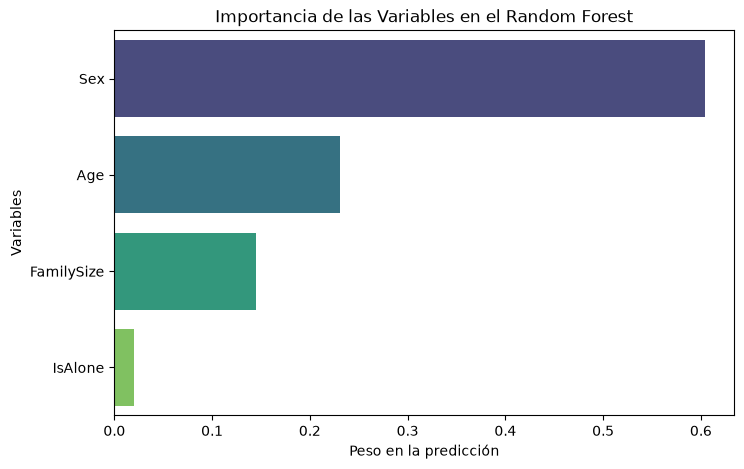

In [5]:
# 6. Analizar la interpretabilidad: ¿Qué variables pesaron más en la decisión?
importancias = pd.DataFrame({
    'Variable': features,
    'Importancia': modelo_rf.feature_importances_
}).sort_values(by='Importancia', ascending=False)

# Visualizar la importancia
plt.figure(figsize=(8, 5))
sns.barplot(x='Importancia', y='Variable', data=importancias, palette='viridis')
plt.title('Importancia de las Variables en el Random Forest')
plt.xlabel('Peso en la predicción')
plt.ylabel('Variables')
plt.show()